# Summary 01 · Stilanalyse der Suva-Zusammenfassungen und Prompt v2

**Ziel:** Die Prompts für die DE/FR-Zusammenfassung (`prompts/style_de.md`, `style_fr.md`, `glossary.md`) aus den Daten belegen bzw. korrigieren
und messen, ob ein neuer Prompt mit **Apertus 8B** näher an die Suva-Fassung kommt.

**Daten:** die 55 Suva-Zusammenfassungen (`judgements/Export_*.html`, je DE + FR) und zu jedem Fall der volle Urteilstext (`data/raw/`).

| Teil | Frage |
|---|---|
| A · Form | Länge, Absätze, Satzlänge, Einstieg – DE vs. FR |
| B · Sprache | Einstiegsformeln, Ergebnis-Satz, Zitierweise, typische Wendungen |
| C · Inhalt | Welche Teile des Urteils übernimmt Suva? Wie stark wird verdichtet? |
| D · Terminologie | Wird das Glossar benutzt? Welche Begriffe fehlen? |
| E · Autor / Original | Unterschiede zwischen Autoren und zwischen Original und Übersetzung |
| F · Evaluation | 8B fasst die 55 Urteile zusammen (Leave-one-out), Vergleich mit Suva: Stilmasse, Inhalt, **Apertus 70B als Richter** |

**Annahme Originalsprache:** Die HTML-Dateien haben kein Feld dafür. Der Titel steht immer in der Sprache des Urteils („BGer-Urteil“ / „Arrêt du TF“ / „Sentenza“).
Wir nehmen an: **Original = Sprache des Urteils**, die andere Fassung ist übersetzt. Teil E prüft, ob die Daten dazu passen.

Rechenlogik: `src/hack_apertus_coffee_exe/eval/summary_eval.py`, Tests: `tests/test_eval_summary.py`.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.summary_eval import (
    JUDGE_CRITERIA, JsonlCache, content_match, content_selection, first_words, frequent_terms, glossary_usage,
    judge, judge_items, load_pairs, style_metrics, style_table, term_pairs,
)

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 130, "font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False})
DE, FR, GRAY, INK, GRID = "#257de0", "#f47230", "#9c9c9c", "#191919", "#e6e6e6"

pairs = load_pairs()
style = style_table(pairs)
print(len(pairs), "Suva-Fälle mit DE, FR und Urteilstext")
pd.crosstab(pd.Series([p.author for p in pairs], name="Autor"), pd.Series([p.judgement_language for p in pairs], name="Urteilssprache"))

55 Suva-Fälle mit DE, FR und Urteilstext


Urteilssprache,de,fr,it
Autor,,,
Frei,22,15,1
Lüthi,0,13,1
Villa,0,3,0


## A · Form

In [2]:
cols = ["woerter", "absaetze", "saetze", "woerter_pro_satz"]
form = style.groupby("sprache")[cols].describe(percentiles=[.1, .5, .9]).T.unstack(level=1)
form.loc[:, (slice(None), ["10%", "50%", "90%"])].round(1)

sprache             de                  fr              
                   10%    50%    90%   10%    50%    90%
woerter           66.0  179.0  335.4  85.2  226.0  400.0
absaetze           1.0    3.0    5.0   1.0    3.0    5.0
saetze             3.0    8.0   16.0   3.0    8.0   15.2
woerter_pro_satz  17.3   22.4   31.0  19.8   27.7   39.8

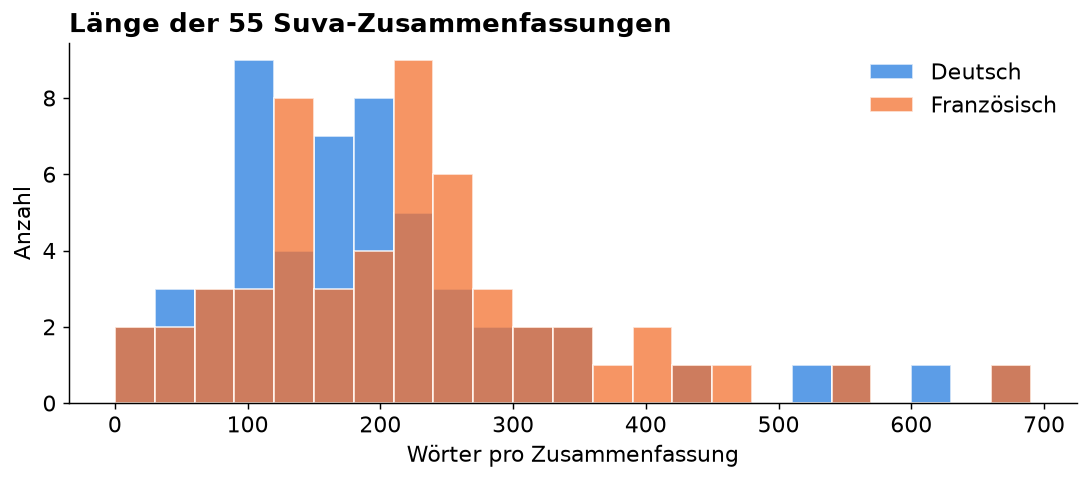

FR/DE-Längenverhältnis: Median 1.19, 10–90 %: 1.05–1.37


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.arange(0, 720, 30)
for lang, color, label in [("de", DE, "Deutsch"), ("fr", FR, "Französisch")]:
    ax.hist(style.loc[style.sprache == lang, "woerter"], bins=bins, color=color, alpha=0.75, label=label,
            edgecolor="white", linewidth=1)
ax.set_xlabel("Wörter pro Zusammenfassung")
ax.set_ylabel("Anzahl")
ax.legend()
ax.set_title("Länge der 55 Suva-Zusammenfassungen")
plt.show()

ratio = pd.Series({p.case_id: len(p.text_fr.split()) / len(p.text_de.split()) for p in pairs})
print(f"FR/DE-Längenverhältnis: Median {ratio.median():.2f}, 10–90 %: {ratio.quantile(.1):.2f}–{ratio.quantile(.9):.2f}")

**Befund A**
- Median **179 Wörter (DE)** und **226 (FR)**, 3 Absätze. Französisch ist im Mittel rund 20 % länger, ein normaler Sprachunterschied.
- Die Spannweite ist gross (8–690 Wörter). Kurze Grundsatz-Notizen und lange Fallschilderungen kommen beide vor.
- Das Stilprofil v1 (DE 100–350 Wörter, FR 100–400) trifft das grob. Präziser: **DE etwa 120–300 Wörter, FR etwa 150–360**, das entspricht dem 10- bis 90-%-Bereich.


## B · Sprache

In [4]:
pd.DataFrame({
    "Einstieg DE": style[style.sprache == "de"].einstieg.value_counts(),
    "Einstieg FR": style[style.sprache == "fr"].einstieg.value_counts(),
}).rename(index={"regel": "mit der Rechtsregel", "fall": "mit Person / Ereignis", "urteil": "«In diesem Urteil …»"})

,Einstieg DE,Einstieg FR
einstieg,,
mit der Rechtsregel,31,29
mit Person / Ereignis,19,21
«In diesem Urteil …»,5,5


In [5]:
print("Häufigste Anfänge DE:"); display(first_words([p.text_de for p in pairs], 2).head(8))
print("Häufigste Anfänge FR:"); display(first_words([p.text_fr for p in pairs], 2).head(8))

Häufigste Anfänge DE:


Der Versicherte          7
In diesem                5
Die Suva                 2
Erwartet der             1
Die Reinigung            1
Am 16.                   1
Die Liste                1
Versicherter Direktor    1
Name: count, dtype: int64

Häufigste Anfänge FR:


L’assuré a       4
Dans cette       3
La Suva          2
Dans cet         2
En cas           2
Un assuré        2
Si l’assureur    1
Le nettoyage     1
Name: count, dtype: int64

In [6]:
b = style.groupby("sprache")[["erwaegungshinweise", "artikelzitate"]].agg(lambda s: (s > 0).mean())
b.columns = ["Anteil mit Erwägungshinweis", "Anteil mit Artikelzitat"]
b["Anteil mit Ergebnis im Schlussabsatz"] = style.groupby("sprache").ergebnis_im_schluss.mean()
b["Anteil mit Ergebnis irgendwo"] = style.groupby("sprache").ergebnis_irgendwo.mean()
b["Anteil nennt «Suva»"] = style.groupby("sprache").nennt_suva.mean()
b.T.style.format("{:.0%}")

sprache,de,fr
Anteil mit Erwägungshinweis,31%,31%
Anteil mit Artikelzitat,40%,40%
Anteil mit Ergebnis im Schlussabsatz,29%,40%
Anteil mit Ergebnis irgendwo,31%,47%
Anteil nennt «Suva»,36%,35%


**Befund B: das Stilprofil v1 verlangt mehr, als Suva tut**

| Stilprofil v1 sagt | Daten zeigen |
|---|---|
| Einstieg mit Rechtsregel **oder** «In diesem Urteil …» | Rechtsregel ist am häufigsten, «In diesem Urteil / Fall» nur bei **5 von 55** |
| Erwägungen zitieren «(E. 5.2)» | Nur etwa **30 %** der Texte nennen überhaupt eine Erwägung |
| Ergebnis als eigener Schlussabsatz | Nur etwa **30 % (DE) / 40 % (FR)** nennen das Ergebnis im Schlussabsatz; die meisten enden mit der Rechtsregel |
| Gesetze zitieren | Etwa die Hälfte nennt einen Artikel, meist nur einen |

→ **Prompt v2:** Einstieg mit der Kernregel als Standard, Erwägungen und Artikel nur sparsam (höchstens 1–2), das Ergebnis nur dann, wenn es für die Praxis zählt (Rückweisung, Gutheissung zugunsten oder zulasten der Suva).


## C · Inhalt: Was übernimmt Suva aus dem Urteil?

In [7]:
sel = pd.DataFrame([x for x in map(content_selection, pairs) if x]).set_index("case_id")
sel.describe().loc[["mean", "50%", "min", "max"]].round(2)

,verdichtung,anteil_sachverhalt,anteil_erwaegungen,anteil_dispositiv,erwaegungen_genutzt,erwaegungen_total,position_genutzt
mean,0.08,0.09,0.87,0.04,2.4,6.43,0.56
50%,0.07,0.00,1.00,0.00,2.0,6.00,0.57
min,0.00,0.00,0.00,0.00,0.0,0.00,0.00
max,0.23,0.35,1.00,1.00,5.0,11.00,1.00


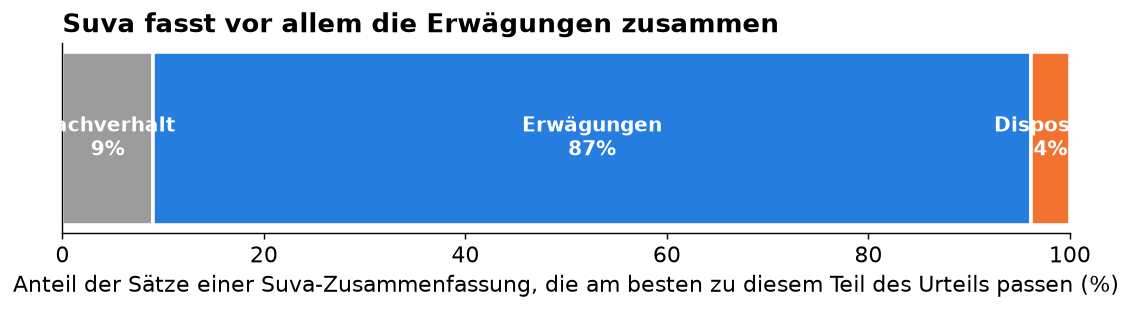

In [8]:
fig, ax = plt.subplots(figsize=(10, 1.9))
parts = [("Sachverhalt", sel.anteil_sachverhalt.mean(), GRAY), ("Erwägungen", sel.anteil_erwaegungen.mean(), DE),
         ("Dispositiv", sel.anteil_dispositiv.mean(), FR)]
left = 0
for label, share, color in parts:
    ax.barh(0, share * 100, left=left, color=color, edgecolor="white", linewidth=2)
    if share > 0.03:
        ax.text(left + share * 50, 0, f"{label}\n{share:.0%}", ha="center", va="center", color="white", fontsize=11,
                fontweight="bold")
    left += share * 100
ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Anteil der Sätze einer Suva-Zusammenfassung, die am besten zu diesem Teil des Urteils passen (%)")
ax.set_title("Suva fasst vor allem die Erwägungen zusammen")
plt.show()

**Befund C**
- **Verdichtung:** Eine Suva-Zusammenfassung hat im Mittel etwa **7 % der Wörter** des Urteils.
- Fast **90 % der Sätze** stammen inhaltlich aus den **Erwägungen**. Sachverhalt und Dispositiv kommen kaum vor.
- Suva nutzt im Mittel **2–3 von rund 6 Haupt-Erwägungen**, eher aus der zweiten Hälfte des Urteils (Position ≈ 0.56). Das ist die materielle Würdigung, nicht Prozessuales am Anfang (Eintreten, Kognition).

→ **Prompt v2:** Sachverhalt höchstens in einem Satz, Fokus auf die 1–3 Erwägungen mit der materiellen Rechtsregel, Prozessuales weglassen.
Im Faktenschritt zusätzlich nach der Erwägung mit der **Kernregel** fragen.

*Methode: TF-IDF-Ähnlichkeit zwischen jedem Satz der Zusammenfassung (in der Urteilssprache) und den Teilen des Urteils. Grobe, aber stabile Zuordnung.*


## D · Terminologie

In [9]:
g = glossary_usage(pairs)
print(f"{len(g)} Glossar-Einträge; nie benutzt: {(g.texte_de == 0).sum()} DE, {(g.textes_fr == 0).sum()} FR")
g.sort_values("texte_de", ascending=False)

58 Glossar-Einträge; nie benutzt: 5 DE, 3 FR


,deutsch,francais,texte_de,textes_fr
13,"versicherte Person, der/die Versicherte",l'assuré/e,54,13
31,Beschwerde (nicht «Rekurs»),recours,35,36
57,Beschwerden (gesundheitlich),troubles,35,10
9,"Bundesgericht, die Bundesrichter","Tribunal fédéral, les juges fédéraux",22,25
54,Leistungen (der Versicherung),prestations,19,19
56,"bestätigen (Entscheid, Rechtsprechung)",confirmer,16,17
10,"Vorinstanz, Kantonsgericht","Cour cantonale, juridiction cantonale, Tribunal cantonal, premiers juges",14,22
55,kantonales Gericht,tribunal cantonal,13,18
28,"Gutachten, Gutachter/in","expertise, expert/e",12,13
1,ATSG,LPGA,12,12


In [10]:
de_terms = frequent_terms([p.text_de for p in pairs], top=80, min_docs=5)
fr_terms = frequent_terms([p.text_fr for p in pairs], top=200, min_docs=4)
glossary_text = Path("prompts/glossary.md").read_text(encoding="utf-8").lower()
missing = [t for t in de_terms.index if len(t) > 6 and t.split()[0] not in glossary_text]
pairs_tbl = term_pairs(pairs, missing[:30], list(fr_terms.index))
pairs_tbl[pairs_tbl.dice >= 0.75]

,deutsch,francais,dice,texte
8,bestätigt,confirmé,0.93,16
0,versicherten,assuré,0.82,29


**Befund D**
- Die meisten Glossar-Einträge kommen in den Suva-Texten vor. Einige gar nicht oder nur einmal, z. B. «Untersuchungsgrundsatz» und «Nichteintreten» als Substantiv.
  Das sind Begriffe aus Urteilen, die Suva selten zusammenfasst. Sie schaden nicht, verlängern aber den Prompt.
- **Verbformen** («abweisen» vs. «abgewiesen») erkennt die Stammsuche nur teilweise. Bei den Einträgen zum Ergebnis ist der Wert «nie benutzt» deshalb zu streng.
- Die Tabelle oben zeigt **häufige Suva-Begriffe, die nicht im Glossar stehen**, mit dem wahrscheinlichsten französischen Gegenstück. Dice ≥ 0.75 heisst: Die Begriffe stehen fast immer in denselben Paaren.
  Die Methode ist grob (z. B. «Beschwerden» ↔ «troubles» stimmt, Funktionswörter rutschen mit). Von Hand geprüfte Paare kamen ins **Glossar v2**:
  Rechtsprechung ↔ jurisprudence, insbesondere ↔ notamment, im vorliegenden Fall ↔ en l'espèce, Leistungen ↔ prestations,
  kantonales Gericht ↔ tribunal cantonal, bestätigen ↔ confirmer, Beschwerden (gesundheitlich) ↔ troubles.


## E · Autor und Original vs. Übersetzung

In [11]:
style["autor_original"] = style.autor + " · " + np.where(style.original, "Original", "Übersetzung")
e = style.groupby(["autor", "sprache", "original"])[["woerter", "woerter_pro_satz", "erwaegungshinweise"]].median()
e["texte"] = style.groupby(["autor", "sprache", "original"]).size()
e

woerter  woerter_pro_satz  erwaegungshinweise  texte
autor sprache original                                                      
Frei  de      False       195.5             20.72                 0.0     16
              True        141.5             21.61                 0.0     22
      fr      False       192.0             27.22                 0.0     23
              True        226.0             27.62                 0.0     15
Lüthi de      False       216.0             23.71                 2.5     14
      fr      False       129.0             32.25                 2.0      1
              True        246.0             30.04                 3.0     13
Villa de      False       283.0             20.08                 3.0      3
      fr      True        287.0             23.92                 3.0      3

In [12]:
by_orig = pd.DataFrame({"FR/DE-Länge": ratio}).join(pd.Series({p.case_id: p.judgement_language for p in pairs}, name="Urteilssprache"))
by_orig.groupby("Urteilssprache")["FR/DE-Länge"].describe()[["count", "50%", "mean"]]

,count,50%,mean
Urteilssprache,,,
de,22.0,1.28,1.27
fr,31.0,1.12,1.14
it,2.0,1.28,1.28


**Befund E**
- **Frei** fasst Urteile in beiden Sprachen zusammen (22 DE, 15 FR, 1 IT), **Lüthi und Villa** nur französische.
- **Erwägungen zitieren ist eine Gewohnheit des Autors:** Lüthi und Villa nennen im Median 2–3 Erwägungen, Frei keine.
  Deshalb soll der Prompt das Zitieren erlauben, aber nicht verlangen.
- **Das Längenverhältnis stützt die Annahme „Original = Urteilssprache“:** Bei deutschen Urteilen ist FR rund 28 % länger als DE, bei französischen nur 12 %.
  Die übersetzte Fassung ist also jeweils länger, wie bei Übersetzungen üblich. Ein Beweis ist das nicht.
- Für den Prompt heisst das: Beispiele in der **Zielsprache aus einem Urteil derselben Sprache** sind am ehesten Originale und damit die besten Stilvorlagen.
  → **Prompt v2:** Beispiele bevorzugt aus Urteilen in der Zielsprache.


## F · Evaluation: Apertus 8B gegen die Suva-Fassung

Apertus 8B fasst alle 55 Urteile mit der Produktions-Pipeline zusammen (`summary.generate.Summarizer`: Fakten → DE → FR → Check).
Das eigene Suva-Beispiel ist nie Vorlage (Leave-one-out). Verglichen wird jede Fassung mit der Suva-Fassung derselben Sprache:
- **Stilmasse** wie in A/B,
- **Inhalt:** Ergebnis, zitierte Artikel, erfundene Erwägungen,
- **Apertus 70B als Richter** mit fester Bewertungsliste (Kernaussage, Ergebnis, Treue, Stil, Sprache, Gesamt; je 1–5).

Die Generierung lief mit `python -m hack_apertus_coffee_exe.eval.summary_eval --out … --prompts-dir …`, die Ergebnisse liegen in `results/tables/summary/`.


In [13]:
RUN_APERTUS = False   # True = fehlende Richter-Urteile beim Gateway holen (Apertus 70B)
VERSIONS = {"v1": ("results/tables/summary/generated_v1_8b.jsonl", "prompts/v1"),
            "v2": ("results/tables/summary/generated_v2_8b.jsonl", "prompts/v2")}
generated = {v: {k: r for k, r in JsonlCache(path).rows.items() if "error" not in r}
             for v, (path, _) in VERSIONS.items() if Path(path).exists()}
for v, rows in generated.items():
    print(v, len(rows), "von", len(pairs), "Urteilen zusammengefasst")

v1 55 von 55 Urteilen zusammengefasst
v2 55 von 55 Urteilen zusammengefasst


In [14]:
rows = []
for p in pairs:
    for lang in ("de", "fr"):
        rows.append({"version": "Suva", "case_id": p.case_id, "sprache": lang, **style_metrics(p.text(lang), lang)})
        for v, gen in generated.items():
            if p.case_id in gen:
                text = gen[p.case_id][lang]
                rows.append({"version": v, "case_id": p.case_id, "sprache": lang, **style_metrics(text, lang),
                             **content_match(p.text(lang), text, p, lang)})
cmp = pd.DataFrame(rows)
common = set.intersection(*[set(g) for g in generated.values()]) if generated else set()
cmp = cmp[cmp.case_id.isin(common)]
summary_style = cmp.groupby(["version", "sprache"]).agg(
    woerter=("woerter", "median"), absaetze=("absaetze", "median"), woerter_pro_satz=("woerter_pro_satz", "median"),
    mit_erwaegung=("erwaegungshinweise", lambda s: (s > 0).mean()), mit_artikel=("artikelzitate", lambda s: (s > 0).mean()),
    ergebnis_im_schluss=("ergebnis_im_schluss", "mean"),
    einstieg_regel=("einstieg", lambda s: (s == "regel").mean()), einstieg_urteil=("einstieg", lambda s: (s == "urteil").mean()),
)
print(f"{len(common)} Urteile, die in allen Versionen vorliegen")
summary_style.round(2)

55 Urteile, die in allen Versionen vorliegen


woerter  absaetze  woerter_pro_satz  mit_erwaegung  \
version sprache                                                       
Suva    de         179.0       3.0             22.43           0.31   
        fr         226.0       3.0             27.67           0.31   
v1      de         160.0       2.0             15.11           0.31   
        fr         116.0       1.0             26.38           0.33   
v2      de          83.0       1.0             16.00           0.04   
        fr         101.0       1.0             24.75           0.07   

                 mit_artikel  ergebnis_im_schluss  einstieg_regel  \
version sprache                                                     
Suva    de              0.40                 0.29            0.56   
        fr              0.40                 0.40            0.53   
v1      de              0.47                 0.71            0.16   
        fr              0.45                 0.95            0.02   
v2      de              0.35                 0.58            0.84   
        fr              0.53                 0.89            0.82   

                 einstieg_urteil  
version sprache                   
Suva    de                  0.09  
        fr                  0.09  
v1      de                  0.69  
        fr                  0.95  
v2      de                  0.00  
        fr                  0.00

In [15]:
content = cmp[cmp.version != "Suva"].groupby(["version", "sprache"]).agg(
    laenge_vs_suva=("laenge_verhaeltnis", "median"), artikel_jaccard=("artikel_jaccard", "mean"),
    suva_artikel_gefunden=("artikel_suva_gefunden", "mean"), erfundene_erwaegungen=("erwaegungen_erfunden", "sum"))
content.round(2)

laenge_vs_suva  artikel_jaccard  suva_artikel_gefunden  \
version sprache                                                           
v1      de                 0.87             0.53                   0.48   
        fr                 0.57             0.62                   0.52   
v2      de                 0.46             0.65                   0.43   
        fr                 0.62             0.57                   0.44   

                 erfundene_erwaegungen  
version sprache                         
v1      de                         1.0  
        fr                        10.0  
v2      de                         0.0  
        fr                         0.0

In [16]:
judged = {}
for v, gen in generated.items():
    items = [i for i in judge_items(pairs, gen, v) if i["key"].split("|")[1] in common]
    path = f"results/tables/summary/judge_{v}_70b.jsonl"
    cache = judge(items, path) if RUN_APERTUS else JsonlCache(path)
    judged[v] = pd.DataFrame([{**r, "textsprache": k.split("|")[2]} for k, r in cache.rows.items()
                              if "error" not in r and k.split("|")[1] in common])
scores = pd.concat([d.assign(version=v, case=d.key.str.split("|").str[1]) for v, d in judged.items() if len(d)])
# fair: only texts that the judge graded in every version
both = scores.groupby(["case", "textsprache"]).version.nunique()
both = both[both == scores.version.nunique()].index
scores = scores.set_index(["case", "textsprache"]).loc[both].reset_index()
scores[list(JUDGE_CRITERIA)] = scores[list(JUDGE_CRITERIA)].apply(pd.to_numeric, errors="coerce")
print(f"{len(both)} Texte (Fall × Sprache) in allen Versionen bewertet; Richter ohne gültige Antwort: "
      f"{110 * len(judged) - len(scores)} Bewertungen")
scores.groupby(["version", "textsprache"])[list(JUDGE_CRITERIA)].mean().round(2)

103 Texte (Fall × Sprache) in allen Versionen bewertet; Richter ohne gültige Antwort: 14 Bewertungen


kernaussage  ergebnis  treue  stil  sprache  gesamt
version textsprache                                                     
v1      de                  2.04      2.12   2.22  1.86     2.86    2.00
        fr                  2.52      2.69   2.50  2.19     3.09    2.46
v2      de                  2.55      2.76   2.51  2.24     3.18    2.39
        fr                  2.57      3.02   2.44  2.22     3.19    2.43

### Stil im Vergleich

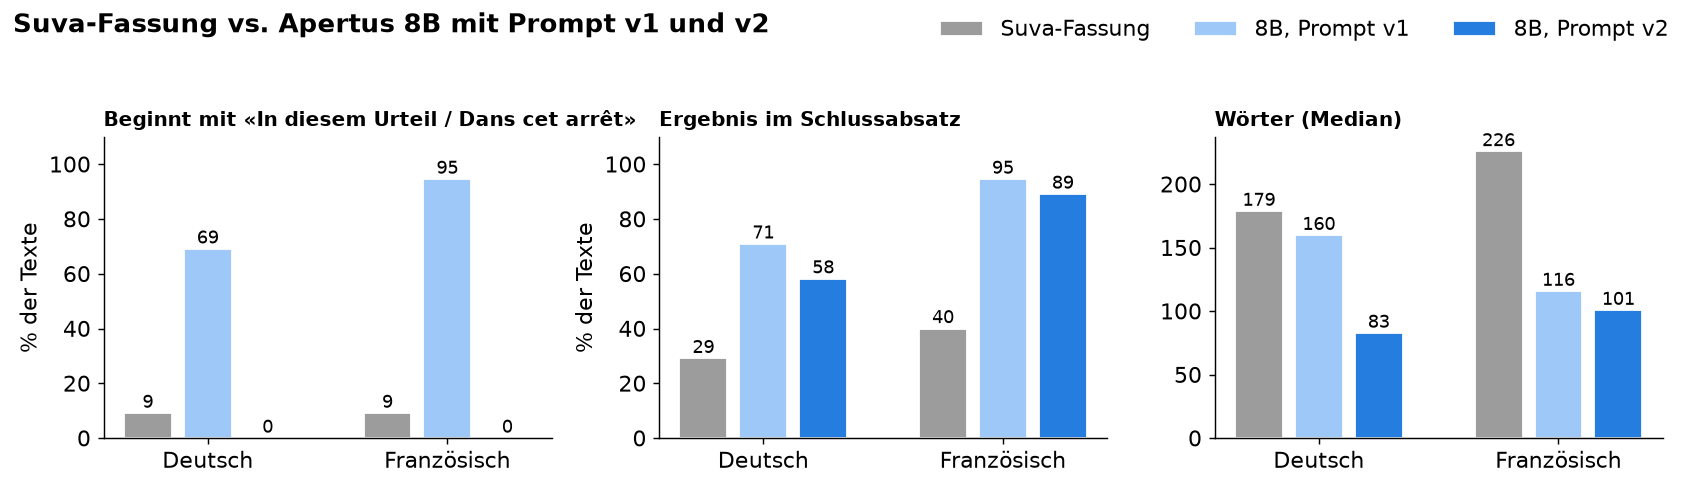

In [17]:
share = cmp.groupby(["version", "sprache"]).agg(
    einstieg_urteil=("einstieg", lambda s: (s == "urteil").mean()), ergebnis_im_schluss=("ergebnis_im_schluss", "mean"))
labels = {"einstieg_urteil": "Beginnt mit «In diesem Urteil / Dans cet arrêt»", "ergebnis_im_schluss": "Ergebnis im Schlussabsatz"}
versions = [v for v in ["Suva", "v1", "v2"] if v in share.index.get_level_values(0)]
colors = {"Suva": GRAY, "v1": "#9dc8f7", "v2": DE}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes[:2], labels):
    for j, lang in enumerate(["de", "fr"]):
        for k, v in enumerate(versions):
            val = share.loc[(v, lang), metric] * 100
            ax.bar(j * (len(versions) + 1) + k, val, color=colors[v], edgecolor="white", label=v if j == 0 else None)
            ax.text(j * (len(versions) + 1) + k, val + 2, f"{val:.0f}", ha="center", fontsize=10)
    ax.set_xticks([(len(versions) - 1) / 2, len(versions) + 1 + (len(versions) - 1) / 2], ["Deutsch", "Französisch"])
    ax.set_ylim(0, 110)
    ax.set_title(labels[metric], fontsize=11)
    ax.set_ylabel("% der Texte")
ax = axes[2]
med = cmp.groupby(["version", "sprache"]).woerter.median()
for j, lang in enumerate(["de", "fr"]):
    for k, v in enumerate(versions):
        ax.bar(j * (len(versions) + 1) + k, med[(v, lang)], color=colors[v], edgecolor="white")
        ax.text(j * (len(versions) + 1) + k, med[(v, lang)] + 4, f"{med[(v, lang)]:.0f}", ha="center", fontsize=10)
ax.set_xticks([(len(versions) - 1) / 2, len(versions) + 1 + (len(versions) - 1) / 2], ["Deutsch", "Französisch"])
ax.set_title("Wörter (Median)", fontsize=11)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, ["Suva-Fassung" if n == "Suva" else f"8B, Prompt {n}" for n in names], loc="upper right", ncol=3)
fig.suptitle("Suva-Fassung vs. Apertus 8B mit Prompt v1 und v2", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Bewertung durch Apertus 70B

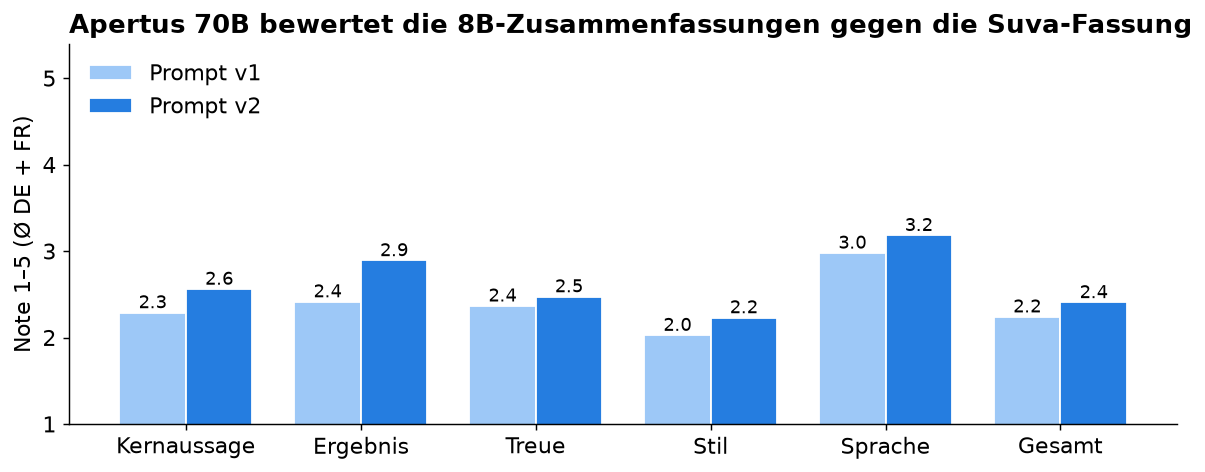

Gesamtnote v2 − v1: Ø +0.17; besser 37, gleich 41, schlechter 25 von 103 Texten


In [18]:
crit = list(JUDGE_CRITERIA)
means = scores.groupby("version")[crit].mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(crit))
w = 0.38
for k, (v, color) in enumerate([("v1", "#9dc8f7"), ("v2", DE)]):
    if v in means.index:
        ax.bar(x + (k - 0.5) * w, means.loc[v], width=w, color=color, edgecolor="white", label=f"Prompt {v}")
        for xi, val in zip(x, means.loc[v]):
            ax.text(xi + (k - 0.5) * w, val + 0.05, f"{val:.1f}", ha="center", fontsize=10)
ax.set_xticks(x, [c.capitalize() for c in crit])
ax.set_ylim(1, 5.4)
ax.set_ylabel("Note 1–5 (Ø DE + FR)")
ax.legend(loc="upper left")
ax.set_title("Apertus 70B bewertet die 8B-Zusammenfassungen gegen die Suva-Fassung")
plt.show()

g = scores.pivot_table(index=["case", "textsprache"], columns="version", values="gesamt")
if {"v1", "v2"} <= set(g.columns):
    d = (g["v2"] - g["v1"]).dropna()
    print(f"Gesamtnote v2 − v1: Ø {d.mean():+.2f}; besser {int((d > 0).sum())}, gleich {int((d == 0).sum())}, schlechter {int((d < 0).sum())} von {len(d)} Texten")

## Fazit

**Was Prompt v2 verbessert hat** (alle 55 Urteile, Apertus 8B, Leave-one-out)

| | Suva | 8B · v1 | 8B · v2 |
|---|---|---|---|
| Beginnt mit «In diesem Urteil / Dans cet arrêt» | 9 % | 69 % / 95 % | **0 % / 0 %** |
| Beginnt mit der Rechtsregel | 56 % / 53 % | 16 % / 2 % | **84 % / 82 %** |
| Erfundene Erwägungsnummern (Summe) | – | 1 / 10 | **0 / 0** |
| Richter 70B, Gesamt (1–5) | – | 2.00 / 2.46 | **2.39 / 2.43** |
| Richter 70B, Kernaussage (1–5) | – | 2.04 / 2.52 | **2.55 / 2.57** |

(Werte DE / FR)

**Was noch nicht stimmt**
1. **Zu kurz:** v2 schreibt im Median 83 (DE) bzw. 101 (FR) Wörter, meist in einem Absatz. Suva schreibt 179 / 226 Wörter in 3 Absätzen.
   Die Längenvorgabe im Stilprofil allein reicht dem 8B-Modell nicht. Vermutlich wirkt die Anweisung «Prozessuales weglassen, Sachverhalt höchstens 1–2 Sätze» stärker.
2. **Das Ergebnis steht weiter fast immer am Schluss** (58 % / 89 % statt 29 % / 40 %). Die Beispiele und das «verbindliche Dispositiv» im Prompt ziehen stärker als die Regel im Stilprofil.
3. **Die Noten sind absolut tief** (etwa 2.4 von 5). Der Richter bemängelt vor allem ungenaue Kernaussagen und falsch übernommene Rechtsgrundlagen. Das ist die Grenze von 8B mit Urteilsauszug.

**Empfehlung**
- **Prompt v2 übernehmen**, er ist in den Noten und bei den Stilmerkmalen besser als v1 und erfindet keine Erwägungen mehr.
- **Nächster Schritt (v3):** Länge konkret im Auftrag nennen («2–3 Absätze, etwa 150–250 Wörter»). Das Dispositiv im Prompt nur noch als Kontrolle angeben, nicht als Pflichtinhalt.
- Beispiele bevorzugt aus Urteilen in der Zielsprache wählen (Teil E, Originale). Dafür braucht es eine kleine Änderung in `summary/examples.py`.

**Grenzen**
- Stilprofil v2 wurde aus denselben 55 Texten abgeleitet, auf denen es gemessen wird. Die Werte sind eher zu günstig, für Stilmasse mehr als für die Richter-Note.
- Richter = Apertus 70B mit fester Liste, ein Lauf. Bei 14 von 220 Bewertungen kam keine gültige Antwort. Verglichen werden nur die 103 Texte, die in beiden Versionen bewertet sind.
- Eine Note von Suva-Juristen fehlt. Eine kleine Handprüfung (etwa 10 Paare) würde die Richter-Note absichern.
